# Is there a repeatable error in the central line?

The intersection of the Sun–Moon axis with Earth already gives a prediction in latitude and longitude. Suppose we know how far that point lies from the NASA central line for several eclipses. Can we use those displacements to improve the path of a later eclipse?

We need `dataset_C.csv`, `df_jpl_complete.csv`, and access to Horizons and the NASA path pages for uncached dates. The comparison proceeds in two stages. First we measure the effect of the time convention on the physical trajectory. We then fit the residual left after the clocks agree.

In [ ]:
%pip install numpy pandas scipy scikit-learn matplotlib pyproj astropy xgboost

In [ ]:
from datetime import date as Date
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import urlopen

import csv
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy.interpolate import CubicHermiteSpline

from astropy.time import Time, TimeDelta
from astropy.coordinates import (
    GCRS,
    ITRS,
    CartesianRepresentation,
    EarthLocation
)
import astropy.units as u

from pyproj import Geod
from xgboost import XGBRegressor


SPEED_OF_LIGHT_KMS = 299792.458
SUN_RADIUS_KM = 695700.0
MOON_RADIUS_KM = 1737.4

EARTH_EQUATORIAL_RADIUS_KM = 6378.137
EARTH_FLATTENING = 1 / 298.257223563
EARTH_POLAR_RADIUS_KM = (
    EARTH_EQUATORIAL_RADIUS_KM * (1 - EARTH_FLATTENING)
)

CACHE_DIRECTORY = Path("cache")
CACHE_DIRECTORY.mkdir(exist_ok=True)

GEOD = Geod(ellps="WGS84")

MONTHS = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]


def validate_date(value):
    return Date.fromisoformat(str(value)).isoformat()


def model_1(date):
    # Placeholder: eclipse classification is not implemented here.
    return None

## Constructing the physical prediction

At time $t$ the columns of $B(t)$ are Earth-fixed axes in celestial coordinates. We rotate position with $B^\top$ and include $\dot B^\top\mathbf r$ in the velocity. From the Moon we trace the ray away from the Sun and solve for its first forward intersection with the WGS84 ellipsoid. An absent intersection means there is no central coordinate to correct at that instant.

In [ ]:
def earth_basis(t):
    """Columns: ITRS basis vectors expressed in GCRS at time t."""
    itrs_axes = ITRS(
        CartesianRepresentation(np.eye(3) * u.km),
        obstime=t
    )

    gcrs_axes = itrs_axes.transform_to(GCRS(obstime=t))

    return gcrs_axes.cartesian.xyz.to_value(u.km)


def rotate_state(t, position, velocity, h=1.0):
    """Transform position and velocity to ITRS coordinates."""
    basis = earth_basis(t)
    delta = TimeDelta(h, format="sec")

    basis_derivative = (
        earth_basis(t + delta) - earth_basis(t - delta)
    ) / (2 * h)

    position = np.asarray(position, dtype=float)
    velocity = np.asarray(velocity, dtype=float)

    position_itrs = basis.T @ position

    velocity_itrs = (
        basis.T @ velocity
        + basis_derivative.T @ position
    )

    return position_itrs, velocity_itrs


def central_point(sun_position, moon_position):
    """Intersect the shadow axis with the WGS84 ellipsoid."""
    sun_position = np.asarray(sun_position, dtype=float)
    moon_position = np.asarray(moon_position, dtype=float)

    if not (
        np.isfinite(sun_position).all()
        and np.isfinite(moon_position).all()
    ):
        return None, "no_central_line"

    direction = moon_position - sun_position
    length = np.linalg.norm(direction)

    if length == 0:
        return None, "no_central_line"

    direction = direction / length

    a = EARTH_EQUATORIAL_RADIUS_KM
    b = EARTH_POLAR_RADIUS_KM

    A = (
        (direction[0]**2 + direction[1]**2) / a**2
        + direction[2]**2 / b**2
    )

    B = 2 * (
        (
            moon_position[0] * direction[0]
            + moon_position[1] * direction[1]
        ) / a**2
        + moon_position[2] * direction[2] / b**2
    )

    C = (
        (moon_position[0]**2 + moon_position[1]**2) / a**2
        + moon_position[2]**2 / b**2
        - 1
    )

    discriminant = B**2 - 4 * A * C

    if discriminant < 0:
        return None, "no_central_line"

    root = np.sqrt(discriminant)

    solutions = [
        (-B - root) / (2 * A),
        (-B + root) / (2 * A)
    ]

    solutions = [value for value in solutions if value >= 0]

    if not solutions:
        return None, "no_central_line"

    point = moon_position + min(solutions) * direction

    moon_distance = np.linalg.norm(point - moon_position)
    sun_distance = np.linalg.norm(point - sun_position)

    moon_angle = np.arcsin(
        np.clip(MOON_RADIUS_KM / moon_distance, 0, 1)
    )

    sun_angle = np.arcsin(
        np.clip(SUN_RADIUS_KM / sun_distance, 0, 1)
    )

    eclipse_type = "total" if moon_angle >= sun_angle else "annular"

    return point, eclipse_type


def longitude_latitude(point):
    """Convert ITRS coordinates in km to WGS84 longitude and latitude."""
    x, y, z = np.asarray(point, dtype=float)

    location = EarthLocation.from_geocentric(
        x, y, z, unit=u.km
    )

    longitude, latitude, _ = location.to_geodetic(
        ellipsoid="WGS84"
    )

    return float(longitude.deg), float(latitude.deg)

## From orbital samples to apparent alignment

The Horizons states are barycentric, sampled every five minutes. Hermite interpolation uses the tabulated velocity as the slope at each endpoint. This lets us evaluate the Moon when the light passed it and the Sun when that light was emitted, while keeping Earth at the reception time. The interpolated terrestrial vectors are in km and their derivatives in km/s.

In [ ]:
def extract_jpl(date):
    """Retrieve barycentric states every five minutes, using the cache."""
    cache_file = (
        CACHE_DIRECTORY
        / f"JPL_barycentric_5min_TDB_{date}.csv"
    )

    # Read earlier project caches when available.
    legacy_file = CACHE_DIRECTORY / f"JPL_baricentrico_5min_TDB_{date}.csv"
    if not cache_file.exists() and legacy_file.exists():
        return pd.read_csv(legacy_file)
    if cache_file.exists():
        return pd.read_csv(cache_file)

    start_time = Time(date, scale="utc")

    start = (
        start_time - TimeDelta(900, format="sec")
    ).tdb.iso

    stop = (
        start_time + TimeDelta(86400 + 300, format="sec")
    ).tdb.iso

    bodies = {
        "earth": "399",
        "moon": "301",
        "sun": "10"
    }

    df = None

    for body, body_id in bodies.items():
        parameters = {
            "format": "text",
            "COMMAND": f"'{body_id}'",
            "CENTER": "'500@0'",
            "MAKE_EPHEM": "'YES'",
            "OBJ_DATA": "'NO'",
            "EPHEM_TYPE": "'VECTORS'",
            "REF_SYSTEM": "'ICRF'",
            "REF_PLANE": "'FRAME'",
            "VEC_CORR": "'NONE'",
            "TIME_TYPE": "'TDB'",
            "OUT_UNITS": "'KM-S'",
            "VEC_TABLE": "'2'",
            "CSV_FORMAT": "'YES'",
            "VEC_LABELS": "'YES'",
            "START_TIME": f"'{start}'",
            "STOP_TIME": f"'{stop}'",
            "STEP_SIZE": "'5 m'"
        }

        text_file = (CACHE_DIRECTORY/ f"JPL_vectors_2x_5min_TDB_{date}_{body}.txt")

        if text_file.exists():
            response = text_file.read_text(encoding="utf-8")

        else:
            url = (
                "https://ssd.jpl.nasa.gov/api/horizons.api?"
                + urlencode(parameters)
            )

            with urlopen(url, timeout=60) as connection:
                response = connection.read().decode("utf-8")

            if "$$SOE" not in response or "$$EOE" not in response:
                raise ValueError(
                    f"Horizons error for {body}: {response[:300]}"
                )

            text_file.write_text(response, encoding="utf-8")

        content = (
            response.split("$$SOE")[1]
            .split("$$EOE")[0]
            .strip()
        )

        rows = list(csv.reader(io.StringIO(content)))

        data = np.array([
            [float(row[i]) for i in (0, 2, 3, 4, 5, 6, 7)]
            for row in rows
        ])

        times = Time(data[:, 0], format="jd", scale="tdb")
        seconds = (times.tai - start_time.tai).to_value("s")

        if df is None:
            df = pd.DataFrame({"seconds": seconds})

        elif not np.allclose(
            df["seconds"], seconds, rtol=0, atol=0.002
        ):
            raise ValueError("The body timestamps do not match.")

        columns = [
            f"{variable}_{body}"
            for variable in (
                "x_km", "y_km", "z_km",
                "vx_kms", "vy_kms", "vz_kms"
            )
        ]

        df[columns] = data[:, 1:]

    df.to_csv(cache_file, index=False)

    return df


def transform_reference_frame(date, df_jpl):
    """Apply the existing light-time approximation and rotate to ITRS."""
    df_jpl = df_jpl.copy()

    # Support cache files produced by the original notebook.
    if "seconds" not in df_jpl.columns:
        df_jpl = df_jpl.rename(columns={"segundos": "seconds"})

    ephemerides = {}

    for body in ("earth", "moon", "sun"):
        position = df_jpl[
            [f"{axis}_km_{body}" for axis in ("x", "y", "z")]
        ].to_numpy()

        velocity = df_jpl[
            [f"{axis}_kms_{body}" for axis in ("vx", "vy", "vz")]
        ].to_numpy()

        ephemerides[body] = CubicHermiteSpline(
            df_jpl["seconds"].to_numpy(),
            position,
            velocity,
            extrapolate=False
        )

    earth = ephemerides["earth"]
    moon = ephemerides["moon"]
    sun = ephemerides["sun"]

    earth_velocity = earth.derivative()
    moon_velocity = moon.derivative()
    sun_velocity = sun.derivative()

    rows = []
    start_time = Time(date, scale="utc")

    for seconds in np.arange(0, 86401, 300):
        earth_position = earth(seconds)

        # Moon-to-Earth light time.
        moon_delay = (
            np.linalg.norm(moon(seconds) - earth_position)
            / SPEED_OF_LIGHT_KMS
        )

        for _ in range(2):
            moon_delay = (
                np.linalg.norm(
                    moon(seconds - moon_delay) - earth_position
                )
                / SPEED_OF_LIGHT_KMS
            )

        moon_time = seconds - moon_delay

        # Sun-to-Moon light time.
        sun_moon_delay = (
            np.linalg.norm(sun(moon_time) - moon(moon_time))
            / SPEED_OF_LIGHT_KMS
        )

        for _ in range(2):
            sun_moon_delay = (
                np.linalg.norm(
                    sun(moon_time - sun_moon_delay)
                    - moon(moon_time)
                )
                / SPEED_OF_LIGHT_KMS
            )

        sun_time = moon_time - sun_moon_delay

        moon_position = moon(moon_time) - earth_position
        sun_position = sun(sun_time) - earth_position

        # Preserve the original first-order velocity approximation.
        moon_v = (
            moon_velocity(moon_time) - earth_velocity(seconds)
        )

        sun_v = (
            sun_velocity(sun_time) - earth_velocity(seconds)
        )

        t = start_time + TimeDelta(float(seconds), format="sec")

        moon_position_itrs, moon_velocity_itrs = rotate_state(
            t, moon_position, moon_v
        )

        sun_position_itrs, sun_velocity_itrs = rotate_state(
            t, sun_position, sun_v
        )

        row = {
            "seconds": seconds,
            "utc": t.utc.isot,
            "moon_light_time_s": moon_delay,
            "sun_moon_light_time_s": sun_moon_delay
        }

        states = [
            ("moon", moon_position_itrs, moon_velocity_itrs),
            ("sun", sun_position_itrs, sun_velocity_itrs)
        ]

        for body, position, velocity in states:
            for axis, value in zip(("x", "y", "z"), position):
                row[f"{axis}_km_{body}"] = value

            for axis, value in zip(("vx", "vy", "vz"), velocity):
                row[f"{axis}_kms_{body}"] = value

        rows.append(row)

    df_itrs = pd.DataFrame(rows)
    interpolators = {}

    for body in ("moon", "sun"):
        position = df_itrs[
            [f"{axis}_km_{body}" for axis in ("x", "y", "z")]
        ].to_numpy()

        velocity = df_itrs[
            [f"{axis}_kms_{body}" for axis in ("vx", "vy", "vz")]
        ].to_numpy()

        interpolators[body] = CubicHermiteSpline(
            df_itrs["seconds"].to_numpy(),
            position,
            velocity,
            extrapolate=False
        )

    return df_itrs, interpolators

The same change in the axis can produce very different displacements on the ground. If $\hat{\mathbf n}$ is the local surface normal, the sensitivity $K=1/|\hat{\mathbf d}\cdot\hat{\mathbf n}|$ grows near a grazing intersection. We include this quantity, the incidence angle, both orbital states, the intersection coordinates and its velocity in the feature table.

In [ ]:
FEATURES = [
    f"{variable}_{body}"
    for body in ("sun", "moon")
    for variable in (
        "x_km", "y_km", "z_km",
        "vx_kms", "vy_kms", "vz_kms"
    )
] + [
    "theta_deg",
    "K",
    "x", "y", "z",
    "lat", "lon",
    "east_velocity_kms",
    "north_velocity_kms",
    "speed_kms"
]


def geometry(df_itrs, interpolators):
    rows = []

    for seconds, utc in zip(df_itrs["seconds"], df_itrs["utc"]):
        sun_position = interpolators["sun"](seconds)
        moon_position = interpolators["moon"](seconds)

        point, eclipse_type = central_point(
            sun_position, moon_position
        )

        row = {
            "seconds": seconds,
            "utc": utc,
            "type": eclipse_type,
            "lat": np.nan,
            "lon": np.nan,
            "x": np.nan,
            "y": np.nan,
            "z": np.nan
        }

        if point is not None:
            lon, lat = longitude_latitude(point)

            row.update(
                lat=lat,
                lon=lon,
                x=point[0],
                y=point[1],
                z=point[2]
            )

        rows.append(row)

    return pd.DataFrame(rows)


def dynamics(df_geometry, interpolators, h=1.0):
    df = df_geometry.copy()

    df["east_velocity_kms"] = np.nan
    df["north_velocity_kms"] = np.nan
    df["speed_kms"] = np.nan

    for index, row in df.dropna(subset=["lat", "lon"]).iterrows():
        seconds = row["seconds"]

        before = max(0, seconds - h)
        after = min(86400, seconds + h)

        previous_point, _ = central_point(
            interpolators["sun"](before),
            interpolators["moon"](before)
        )

        next_point, _ = central_point(
            interpolators["sun"](after),
            interpolators["moon"](after)
        )

        if previous_point is None or next_point is None:
            continue

        velocity = (
            (next_point - previous_point) / (after - before)
        )

        lon, lat = np.deg2rad([row["lon"], row["lat"]])

        east = np.array([
            -np.sin(lon),
            np.cos(lon),
            0
        ])

        north = np.array([
            -np.sin(lat) * np.cos(lon),
            -np.sin(lat) * np.sin(lon),
            np.cos(lat)
        ])

        df.loc[index, "east_velocity_kms"] = np.dot(velocity, east)
        df.loc[index, "north_velocity_kms"] = np.dot(velocity, north)
        df.loc[index, "speed_kms"] = np.linalg.norm(velocity)

    return df


def add_features(date, df_dynamics, interpolators):
    df = df_dynamics.copy()
    df["date"] = date

    seconds = df["seconds"].to_numpy(dtype=float)

    for body in ("sun", "moon"):
        positions = interpolators[body](seconds)
        velocities = interpolators[body].derivative()(seconds)

        for j, axis in enumerate(("x", "y", "z")):
            df[f"{axis}_km_{body}"] = positions[:, j]

        for j, axis in enumerate(("vx", "vy", "vz")):
            df[f"{axis}_kms_{body}"] = velocities[:, j]

    sun_position = df[
        ["x_km_sun", "y_km_sun", "z_km_sun"]
    ].to_numpy()

    moon_position = df[
        ["x_km_moon", "y_km_moon", "z_km_moon"]
    ].to_numpy()

    direction = moon_position - sun_position
    normal = df[["x", "y", "z"]].to_numpy(dtype=float)

    normal = normal / np.array([
        EARTH_EQUATORIAL_RADIUS_KM**2,
        EARTH_EQUATORIAL_RADIUS_KM**2,
        EARTH_POLAR_RADIUS_KM**2
    ])

    with np.errstate(divide="ignore", invalid="ignore"):
        direction = direction / np.linalg.norm(
            direction, axis=1, keepdims=True
        )

        normal = normal / np.linalg.norm(
            normal, axis=1, keepdims=True
        )

        cos_theta = np.abs(
            np.sum(direction * normal, axis=1)
        )

        cos_theta = np.clip(cos_theta, 0, 1)

        df["theta_deg"] = np.degrees(np.arccos(cos_theta))
        df["K"] = 1 / cos_theta

    return df.replace([np.inf, -np.inf], np.nan)

## What should the regressors predict?

At a NASA timestamp, draw the geodesic from the predicted point to the reference point. If its length is $s$ km and its azimuth $A$ is measured clockwise from north, its local components are $e=s\sin A$ and $n=s\cos A$. These signed distances are the two targets. A scalar error alone would tell us how far to move without telling us in which direction.

In [ ]:
def get_event_reference(date, df_C):
    d = Date.fromisoformat(date)

    event = f"SE{d.year}{MONTHS[d.month - 1]}{d.day:02d}"

    reference = df_C[
        df_C["event_id"].str.startswith(event, na=False)
    ].copy()

    reference = reference.dropna(
        subset=["time_ut", "center_lat", "center_lon"]
    )

    return reference


def prepare_training_data(date, interpolators, df_C):
    reference = get_event_reference(date, df_C)

    start_time = Time(date, scale="utc")
    rows = []

    for _, reference_row in reference.iterrows():
        hour = str(reference_row["time_ut"]).strip()

        if ":" not in hour:
            continue

        if hour.count(":") == 1:
            hour += ":00"

        # Preserve the original interpretation of NASA times as UT1.
        t = Time(f"{date} {hour}", scale="ut1")

        seconds = float(
            (t.tai - start_time.tai).to_value("s")
        )

        if not 0 <= seconds <= 86400:
            continue

        sun_position = interpolators["sun"](seconds)
        moon_position = interpolators["moon"](seconds)

        point, eclipse_type = central_point(
            sun_position, moon_position
        )

        if point is None:
            continue

        lon, lat = longitude_latitude(point)

        rows.append({
            "seconds": seconds,
            "utc": t.utc.isot,
            "type": eclipse_type,
            "x": point[0],
            "y": point[1],
            "z": point[2],
            "lat": lat,
            "lon": lon,
            "nasa_lat": float(reference_row["center_lat"]),
            "nasa_lon": float(reference_row["center_lon"]),
            "path_width_km": reference_row.get(
                "path_width_km", np.nan
            )
        })

    if not rows:
        return pd.DataFrame()

    df = (
        pd.DataFrame(rows)
        .sort_values("seconds")
        .drop_duplicates("seconds")
        .reset_index(drop=True)
    )

    df = dynamics(df, interpolators)
    df = add_features(date, df, interpolators)

    azimuth, _, distance_m = GEOD.inv(
        df["lon"].to_numpy(),
        df["lat"].to_numpy(),
        df["nasa_lon"].to_numpy(),
        df["nasa_lat"].to_numpy()
    )

    distance_km = distance_m / 1000
    azimuth = np.deg2rad(azimuth)

    # Signed targets: displacement from the physical model toward NASA.
    df["east_error_km"] = distance_km * np.sin(azimuth)
    df["north_error_km"] = distance_km * np.cos(azimuth)
    df["original_error_km"] = distance_km

    width = pd.to_numeric(
        df["path_width_km"], errors="coerce"
    )

    df["error_percent_width"] = (
        100 * df["original_error_km"] / width.where(width > 0)
    )

    df = df.replace([np.inf, -np.inf], np.nan)

    return df.dropna(subset=[
        "lat",
        "lon",
        "theta_deg",
        "K",
        "east_error_km",
        "north_error_km"
    ]).reset_index(drop=True)

At prediction time the two regressors supply $(\hat e,\hat n)$. We recover the distance $\sqrt{\hat e^2+\hat n^2}$ and bearing $\operatorname{atan2}(\hat e,\hat n)$ and follow that geodesic from the physical point. This also works at high latitude, where a degree of longitude spans a much shorter distance.

In [ ]:
model_2_estimators = None


def model_2(df_dynamics):
    """Predict east/north corrections and apply them on WGS84."""
    if model_2_estimators is None:
        raise ValueError("Train model 2 before requesting corrections.")

    missing = set(FEATURES) - set(df_dynamics.columns)

    if missing:
        raise ValueError(f"Missing features: {sorted(missing)}")

    df = df_dynamics.copy()

    output_columns = [
        "east_correction_km",
        "north_correction_km",
        "corrected_lat",
        "corrected_lon"
    ]

    df[output_columns] = np.nan

    X = df[FEATURES].replace([np.inf, -np.inf], np.nan)

    valid = (
        np.isfinite(df["lat"])
        & np.isfinite(df["lon"])
        & np.isfinite(df["theta_deg"])
        & np.isfinite(df["K"])
    )

    if not valid.any():
        return df

    east = model_2_estimators["east"].predict(X.loc[valid])
    north = model_2_estimators["north"].predict(X.loc[valid])

    azimuth = np.degrees(np.arctan2(east, north))
    distance_m = 1000 * np.hypot(east, north)

    corrected_lon, corrected_lat, _ = GEOD.fwd(
        df.loc[valid, "lon"].to_numpy(),
        df.loc[valid, "lat"].to_numpy(),
        azimuth,
        distance_m
    )

    df.loc[valid, "east_correction_km"] = east
    df.loc[valid, "north_correction_km"] = north
    df.loc[valid, "corrected_lat"] = corrected_lat
    df.loc[valid, "corrected_lon"] = corrected_lon

    return df


def run(date_input, df_C=None, apply_correction=True):
    date = validate_date(date_input)

    if model_1(date) is False:
        return None

    if apply_correction and model_2_estimators is None:
        raise ValueError(
            "Train model 2 first, or use apply_correction=False."
        )

    df_jpl = extract_jpl(date)

    df_itrs, interpolators = transform_reference_frame(
        date, df_jpl
    )

    df_geometry = geometry(df_itrs, interpolators)

    df_dynamics = dynamics(
        df_geometry, interpolators
    )

    df_dynamics = add_features(
        date, df_dynamics, interpolators
    )

    if apply_correction:
        df_dynamics = model_2(df_dynamics)

    df_training = pd.DataFrame()

    if df_C is not None:
        df_training = prepare_training_data(
            date, interpolators, df_C
        )

    return {
        "date": date,
        "jpl": df_jpl,
        "itrs": df_itrs,
        "geometry": df_geometry,
        "dynamics": df_dynamics,
        "training": df_training
    }

## Collecting matched observations

Start with the known eclipse days and turn off the learned correction. A partial eclipse can contribute no central-line targets. Each retained row represents one matched instant, so long tracks can contribute many more rows than short ones.

In [ ]:
df_C = pd.read_csv("dataset_C.csv")
df_jpl_complete = pd.read_csv("df_jpl_complete.csv")

df_jpl_eclipse = df_jpl_complete[
    df_jpl_complete["eclipse"] == 1
].copy()

training_dates = df_jpl_eclipse["reference_day"].dropna().unique()
training_dates = sorted(training_dates)

training_tables = []

for date in training_dates:
    date = str(date).strip()[:10]
    print("Processing:", date)

    result = run(
        date,
        df_C=df_C,
        apply_correction=False
    )

    table = result["training"]
    training_tables.append(table)

    print("Collected rows:", len(table))

df_training = pd.concat(training_tables, ignore_index=True)
df_training = df_training.drop_duplicates(["date", "seconds"])
df_training = df_training.sort_values(["date", "seconds"])
df_training = df_training.reset_index(drop=True)

print("Total rows:", len(df_training))
print("Total eclipses:", df_training["date"].nunique())

display(df_training.head())

In [ ]:
df_training.to_csv("model_2_training_data.csv", index=False)

## Could a clock difference explain the residual?

The path tables specify UT1, tied to Earth rotation. The ephemerides require a dynamical instant. Adopting $\Delta T=\mathrm{TT}-\mathrm{UT1}$ determines which TT instant corresponds to the tabulated clock reading. If those conventions disagree by several seconds, we compare points from different stages of a moving eclipse. We test four dates using the same reference instants with each choice of $\Delta T$.

In [ ]:
NASA_DELTA_T = {
    "2017-08-21": 68.4,
    "2030-11-25": 77.3,
    "2039-12-15": 83.8,
    "2050-05-20": 94.5
}


def reference_time(date, hour, delta_t=None):
    label = f"{date} {hour}"

    if delta_t is None:
        return Time(label, scale="ut1")

    # Construct TT from the numerical UT1 date and time.
    t = Time(label, scale="tt")
    t = t + TimeDelta(delta_t, format="sec")

    # Coordinate difference between TT and UTC, in seconds.
    tt_minus_utc = (
        (t.tt.jd1 - t.utc.jd1)
        + (t.tt.jd2 - t.utc.jd2)
    ) * 86400

    # Make the Earth rotation consistent with the chosen delta T.
    t.delta_ut1_utc = tt_minus_utc - delta_t

    return t

In [ ]:
def compare_delta_t(date, delta_t, df_C):
    df_jpl = extract_jpl(date).copy()

    # Support cache files from the original notebook.
    if "seconds" not in df_jpl.columns:
        df_jpl = df_jpl.rename(columns={"segundos": "seconds"})

    start_time = Time(date, scale="utc")
    ephemerides = {}

    for body in ("earth", "moon", "sun"):
        position = df_jpl[
            [f"{axis}_km_{body}" for axis in ("x", "y", "z")]
        ].to_numpy()

        velocity = df_jpl[
            [f"{axis}_kms_{body}" for axis in ("vx", "vy", "vz")]
        ].to_numpy()

        ephemerides[body] = CubicHermiteSpline(
            df_jpl["seconds"].to_numpy(),
            position,
            velocity,
            extrapolate=False
        )

    earth = ephemerides["earth"]
    moon = ephemerides["moon"]
    sun = ephemerides["sun"]

    reference = get_event_reference(date, df_C)
    rows = []

    for _, data in reference.iterrows():
        hour = str(data["time_ut"]).strip()

        if ":" not in hour:
            continue

        if hour.count(":") == 1:
            hour += ":00"

        original_time = reference_time(date, hour)

        original_delta_t = (
            (original_time.tt.jd1 - original_time.ut1.jd1)
            + (original_time.tt.jd2 - original_time.ut1.jd2)
        ) * 86400

        row = {
            "date": date,
            "time_ut": hour,
            "original_delta_t_s": original_delta_t,
            "nasa_delta_t_s": delta_t
        }

        cases = [
            ("original", None),
            ("aligned", delta_t)
        ]

        for name, value in cases:
            t = reference_time(date, hour, value)

            seconds = float(
                (t.tai - start_time.tai).to_value("s")
            )

            earth_position = earth(seconds)

            # Moon-to-Earth light time.
            moon_delay = (
                np.linalg.norm(moon(seconds) - earth_position)
                / SPEED_OF_LIGHT_KMS
            )

            for _ in range(2):
                moon_delay = (
                    np.linalg.norm(
                        moon(seconds - moon_delay) - earth_position
                    )
                    / SPEED_OF_LIGHT_KMS
                )

            moon_time = seconds - moon_delay

            # Sun-to-Moon light time.
            sun_delay = (
                np.linalg.norm(
                    sun(moon_time) - moon(moon_time)
                )
                / SPEED_OF_LIGHT_KMS
            )

            for _ in range(2):
                sun_delay = (
                    np.linalg.norm(
                        sun(moon_time - sun_delay) - moon(moon_time)
                    )
                    / SPEED_OF_LIGHT_KMS
                )

            sun_time = moon_time - sun_delay

            moon_position = moon(moon_time) - earth_position
            sun_position = sun(sun_time) - earth_position

            if not (
                np.isfinite(moon_position).all()
                and np.isfinite(sun_position).all()
            ):
                raise ValueError(
                    "JPL interpolation is outside its time coverage."
                )

            # Rotate using the same time convention as the ephemerides.
            basis = earth_basis(t)

            sun_itrs = basis.T @ sun_position
            moon_itrs = basis.T @ moon_position

            point, _ = central_point(sun_itrs, moon_itrs)

            row[f"{name}_error_km"] = np.nan

            if point is not None:
                lon, lat = longitude_latitude(point)

                _, _, distance_m = GEOD.inv(
                    lon,
                    lat,
                    data["center_lon"],
                    data["center_lat"]
                )

                row[f"{name}_error_km"] = distance_m / 1000

        rows.append(row)

    return pd.DataFrame(rows)

In [ ]:
comparison_tables = []
summary_rows = []

for date, delta_t in NASA_DELTA_T.items():
    print("Processing:", date)

    table = compare_delta_t(date, delta_t, df_C)
    comparison_tables.append(table)

    # Compare exactly the same reference points in both cases.
    paired = table.dropna(subset=[
        "original_error_km",
        "aligned_error_km"
    ])

    original_mean = paired["original_error_km"].mean()
    aligned_mean = paired["aligned_error_km"].mean()

    summary_rows.append({
        "date": date,
        "reference_points": len(table),
        "paired_points": len(paired),
        "original_delta_t_s": paired["original_delta_t_s"].mean(),
        "nasa_delta_t_s": delta_t,
        "original_mean_km": original_mean,
        "aligned_mean_km": aligned_mean,
        "improvement_percent": (
            100 * (1 - aligned_mean / original_mean)
            if original_mean > 0 else np.nan
        )
    })

df_time_comparison = pd.concat(
    comparison_tables,
    ignore_index=True
)

df_time_summary = pd.DataFrame(summary_rows)

display(df_time_summary.round(3))

df_plot = df_time_comparison[
    df_time_comparison["date"] == "2050-05-20"
].copy()

df_plot["plot_time"] = pd.to_datetime(
    df_plot["date"] + " " + df_plot["time_ut"]
)

fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

axes[0].plot(
    df_plot["plot_time"],
    df_plot["original_error_km"],
    label="Original time convention"
)

axes[0].plot(
    df_plot["plot_time"],
    df_plot["aligned_error_km"],
    label="NASA delta T"
)

axes[0].set_title("Physical model — 2050-05-20")
axes[0].set_ylabel("Geodesic error (km)")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    df_plot["plot_time"],
    df_plot["aligned_error_km"],
    color="darkorange",
    marker=".",
    label="NASA delta T — detailed view"
)

axes[1].set_xlabel("UT1")
axes[1].set_ylabel("Geodesic error (km)")
axes[1].grid(alpha=0.3)
axes[1].legend()

axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M")
)

plt.tight_layout()
plt.show()

On 20 May 2050, adopting the path table’s 94.5 s reduced the recorded mean displacement from 38.814 km to 0.838 km. On 21 August 2017 the corresponding change was 1.313 km to 0.577 km. A substantial part of the apparent error was already explained by the time convention. We therefore recompute the training targets before asking a regressor to learn what remains.

In [ ]:
import re
import html
from urllib.parse import urljoin


# 1. Read the NASA path index and cache it.

reference_catalog = df_C.copy()

index_url = "https://eclipse.gsfc.nasa.gov/SEpath/SEpath.html"
index_file = CACHE_DIRECTORY / "NASA_path_index.html"

if index_file.exists():
    index_text = index_file.read_text(encoding="utf-8")
else:
    with urlopen(index_url, timeout=60) as connection:
        index_text = connection.read().decode("utf-8")

    index_file.write_text(index_text, encoding="utf-8")

path_links = re.findall(
    r'href=["\']([^"\']+path\.html)["\']',
    index_text
)

nasa_path_urls = {}

for link in path_links:
    event_id = link.split("/")[-1].replace("path.html", "")
    nasa_path_urls[event_id] = urljoin(index_url, link)


def get_nasa_delta_t(date, catalog):
    reference = get_event_reference(date, catalog)

    if reference.empty:
        raise ValueError(f"No NASA central-line reference for {date}.")

    event_id = reference["event_id"].iloc[0]
    cache_file = CACHE_DIRECTORY / f"{event_id}_NASA_path.html"

    if cache_file.exists():
        page = cache_file.read_text(encoding="utf-8")
    else:
        url = nasa_path_urls[event_id]

        with urlopen(url, timeout=60) as connection:
            page = connection.read().decode("utf-8")

        cache_file.write_text(page, encoding="utf-8")

    text = html.unescape(re.sub(r"<[^>]+>", " ", page))

    match = re.search(
        r"ΔT\s*=\s*([0-9]+(?:\.[0-9]+)?)",
        text
    )

    if match is None:
        raise ValueError(f"NASA delta T was not found for {date}.")

    return float(match.group(1))

The NASA path page supplies an event-specific time difference. We use it for the ephemeris instant and for the orientation of Earth so that the two parts of the calculation agree.

In [ ]:
# 2. Construct a physical instant from a NASA UT1 timestamp.

def nasa_reference_time(date, hour, delta_t):
    t = Time(f"{date} {hour}", scale="tt")
    t = t + TimeDelta(delta_t, format="sec")

    tt_minus_utc = (
        (t.tt.jd1 - t.utc.jd1)
        + (t.tt.jd2 - t.utc.jd2)
    ) * 86400

    t.delta_ut1_utc = tt_minus_utc - delta_t

    return t


# 3. Calculate light-time-corrected positions in aligned ITRS.

def aligned_states(t, start_time, ephemerides, delta_t):
    t = t.copy()

    tt_minus_utc = (
        (t.tt.jd1 - t.utc.jd1)
        + (t.tt.jd2 - t.utc.jd2)
    ) * 86400

    t.delta_ut1_utc = tt_minus_utc - delta_t

    seconds = float(
        (t.tai - start_time.tai).to_value("s")
    )

    earth = ephemerides["earth"]
    moon = ephemerides["moon"]
    sun = ephemerides["sun"]

    earth_position = earth(seconds)

    moon_delay = (
        np.linalg.norm(moon(seconds) - earth_position)
        / SPEED_OF_LIGHT_KMS
    )

    for _ in range(2):
        moon_delay = (
            np.linalg.norm(
                moon(seconds - moon_delay) - earth_position
            )
            / SPEED_OF_LIGHT_KMS
        )

    moon_time = seconds - moon_delay

    sun_delay = (
        np.linalg.norm(sun(moon_time) - moon(moon_time))
        / SPEED_OF_LIGHT_KMS
    )

    for _ in range(2):
        sun_delay = (
            np.linalg.norm(
                sun(moon_time - sun_delay) - moon(moon_time)
            )
            / SPEED_OF_LIGHT_KMS
        )

    basis = earth_basis(t)

    sun_position = basis.T @ (
        sun(moon_time - sun_delay) - earth_position
    )

    moon_position = basis.T @ (
        moon(moon_time) - earth_position
    )

    if not (
        np.isfinite(sun_position).all()
        and np.isfinite(moon_position).all()
    ):
        raise ValueError("JPL time coverage is insufficient.")

    return sun_position, moon_position

Changing the instant changes the intersection, its velocity, and the angle of incidence. Rebuilding these features together keeps the training examples physically consistent.

In [ ]:
# 4. Recalculate geometry, velocities, and all model features.

def build_aligned_table(date, times, delta_t, df_jpl):
    df_jpl = df_jpl.copy()

    if "seconds" not in df_jpl.columns:
        df_jpl = df_jpl.rename(columns={"segundos": "seconds"})

    start_time = Time(date, scale="utc")
    ephemerides = {}

    for body in ("earth", "moon", "sun"):
        position = df_jpl[
            [f"{axis}_km_{body}" for axis in ("x", "y", "z")]
        ].to_numpy()

        velocity = df_jpl[
            [f"{axis}_kms_{body}" for axis in ("vx", "vy", "vz")]
        ].to_numpy()

        ephemerides[body] = CubicHermiteSpline(
            df_jpl["seconds"].to_numpy(),
            position,
            velocity,
            extrapolate=False
        )

    rows = []
    step = TimeDelta(1.0, format="sec")

    for t in times:
        sun_position, moon_position = aligned_states(
            t, start_time, ephemerides, delta_t
        )

        before = aligned_states(
            t - step, start_time, ephemerides, delta_t
        )

        after = aligned_states(
            t + step, start_time, ephemerides, delta_t
        )

        point, eclipse_type = central_point(
            sun_position, moon_position
        )

        row = {
            "date": date,
            "utc": t.utc.isot,
            "seconds": float(
                (t.tai - start_time.tai).to_value("s")
            ),
            "delta_t_s": delta_t,
            "type": eclipse_type
        }

        for column in FEATURES:
            row[column] = np.nan

        # Velocities are finite differences of the aligned states.
        positions = (sun_position, moon_position)

        for j, body in enumerate(("sun", "moon")):
            velocity = (after[j] - before[j]) / 2.0

            for axis, value in zip(("x", "y", "z"), positions[j]):
                row[f"{axis}_km_{body}"] = value

            for axis, value in zip(("vx", "vy", "vz"), velocity):
                row[f"{axis}_kms_{body}"] = value

        if point is not None:
            lon, lat = longitude_latitude(point)

            row.update(
                x=point[0],
                y=point[1],
                z=point[2],
                lat=lat,
                lon=lon
            )

            direction = moon_position - sun_position
            direction = direction / np.linalg.norm(direction)

            normal = point / np.array([
                EARTH_EQUATORIAL_RADIUS_KM**2,
                EARTH_EQUATORIAL_RADIUS_KM**2,
                EARTH_POLAR_RADIUS_KM**2
            ])

            normal = normal / np.linalg.norm(normal)

            cosine = np.clip(
                abs(np.dot(direction, normal)), 0, 1
            )

            row["theta_deg"] = np.degrees(np.arccos(cosine))
            row["K"] = 1 / cosine if cosine > 0 else np.nan

            previous_point, _ = central_point(before[0], before[1])
            next_point, _ = central_point(after[0], after[1])

            if previous_point is not None and next_point is not None:
                velocity = (next_point - previous_point) / 2.0

                longitude, latitude = np.deg2rad([lon, lat])

                east = np.array([
                    -np.sin(longitude),
                    np.cos(longitude),
                    0
                ])

                north = np.array([
                    -np.sin(latitude) * np.cos(longitude),
                    -np.sin(latitude) * np.sin(longitude),
                    np.cos(latitude)
                ])

                row["east_velocity_kms"] = np.dot(velocity, east)
                row["north_velocity_kms"] = np.dot(velocity, north)
                row["speed_kms"] = np.linalg.norm(velocity)

        rows.append(row)

    return pd.DataFrame(rows)


# 5. Calculate the new training targets at NASA reference times.

def prepare_aligned_training(date, delta_t, catalog, df_jpl):
    reference = get_event_reference(date, catalog).copy()

    reference = reference[
        reference["time_ut"].astype(str).str.contains(":")
    ]

    reference = (
        reference.drop_duplicates("time_ut")
        .sort_values("time_ut")
        .reset_index(drop=True)
    )

    if reference.empty:
        return pd.DataFrame()

    times = []

    for hour in reference["time_ut"]:
        hour = str(hour).strip()

        if hour.count(":") == 1:
            hour += ":00"

        times.append(nasa_reference_time(date, hour, delta_t))

    df = build_aligned_table(date, times, delta_t, df_jpl)

    df["time_ut"] = reference["time_ut"].to_numpy()
    df["nasa_lat"] = reference["center_lat"].to_numpy(dtype=float)
    df["nasa_lon"] = reference["center_lon"].to_numpy(dtype=float)

    df["path_width_km"] = pd.to_numeric(
        reference["path_width_km"], errors="coerce"
    ).to_numpy()

    # A central-line target requires a physical intersection.
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=["lat", "lon", "theta_deg", "K"]).copy()

    azimuth, _, distance_m = GEOD.inv(
        df["lon"].to_numpy(),
        df["lat"].to_numpy(),
        df["nasa_lon"].to_numpy(),
        df["nasa_lat"].to_numpy()
    )

    azimuth = np.deg2rad(azimuth)
    distance_km = distance_m / 1000

    df["east_error_km"] = distance_km * np.sin(azimuth)
    df["north_error_km"] = distance_km * np.cos(azimuth)
    df["original_error_km"] = distance_km

    width = df["path_width_km"].where(df["path_width_km"] > 0)

    df["error_percent_width"] = (
        100 * df["original_error_km"] / width
    )

    return df.reset_index(drop=True)


# 6. Update prediction so it uses the same aligned features.

def run(date_input, df_C=None, apply_correction=True, delta_t=None):
    date = validate_date(date_input)

    if model_1(date) is False:
        return None

    if apply_correction and model_2_estimators is None:
        raise ValueError("Retrain model 2 using the aligned dataset first.")

    catalog = reference_catalog if df_C is None else df_C

    # An explicit delta_t can be supplied for dates outside the catalog.
    if delta_t is None:
        delta_t = get_nasa_delta_t(date, catalog)

    df_jpl = extract_jpl(date)
    start_time = Time(date, scale="utc")

    times = [
        start_time + TimeDelta(float(s), format="sec")
        for s in np.arange(0, 86401, 300)
    ]

    df_dynamics = build_aligned_table(
        date, times, delta_t, df_jpl
    )

    if apply_correction:
        df_dynamics = model_2(df_dynamics)

    training = pd.DataFrame()

    if df_C is not None:
        training = prepare_aligned_training(
            date, delta_t, df_C, df_jpl
        )

    state_columns = [
        f"{variable}_{body}"
        for body in ("sun", "moon")
        for variable in (
            "x_km", "y_km", "z_km",
            "vx_kms", "vy_kms", "vz_kms"
        )
    ]

    return {
        "date": date,
        "delta_t_s": delta_t,
        "jpl": df_jpl,
        "itrs": df_dynamics[["seconds", "utc"] + state_columns].copy(),
        "geometry": df_dynamics[
            ["seconds", "utc", "type", "lat", "lon", "x", "y", "z"]
        ].copy(),
        "dynamics": df_dynamics,
        "training": training
    }

Rebuild the matched table at the reference times and discard any fitted estimators from the earlier convention. The fit below uses these updated rows.

In [ ]:
# 7. Rebuild the dataset for the dates previously collected.
# Old regressors are invalid for the updated physical pipeline.

model_2_estimators = None

dates_to_recalculate = sorted(df_training["date"].unique())
aligned_tables = []

for date in dates_to_recalculate:
    delta_t = get_nasa_delta_t(date, reference_catalog)
    df_jpl = extract_jpl(date)

    table = prepare_aligned_training(
        date, delta_t, reference_catalog, df_jpl
    )

    aligned_tables.append(table)

    print(
        date,
        "| NASA delta T:", delta_t,
        "| Rows:", len(table),
        "| Mean error (km):",
        round(table["original_error_km"].mean(), 3)
        if not table.empty else np.nan
    )

df_training = pd.concat(aligned_tables, ignore_index=True)

df_training = (
    df_training
    .drop_duplicates(["date", "seconds"])
    .sort_values(["date", "seconds"])
    .reset_index(drop=True)
)

df_training.to_csv(
    "model_2_training_data_aligned.csv",
    index=False
)

print("\nTotal rows:", len(df_training))
print("Total eclipses:", df_training["date"].nunique())
print("Saved: model_2_training_data_aligned.csv")


display(df_training.head())

## Holding out complete eclipses

Adjacent points on a track share nearly the same geometry. Splitting rows at random would put parts of the same event in both sets. We sort the eclipses by date and reserve the last fifth in their entirety. Each earlier eclipse receives the same total training weight. Two boosted-tree regressors minimize squared residuals, one for each local direction.

In [ ]:
dates = sorted(df_training["date"].unique())

if len(dates) < 3:
    raise ValueError(
        "Collect at least three different eclipses "
        "before splitting training and test data."
    )

number_of_test_dates = max(
    1, int(np.ceil(0.20 * len(dates)))
)

train_dates = dates[:-number_of_test_dates]
test_dates = dates[-number_of_test_dates:]

df_train = df_training[
    df_training["date"].isin(train_dates)
].copy()

df_test = df_training[
    df_training["date"].isin(test_dates)
].copy()

X_train = df_train[FEATURES].replace(
    [np.inf, -np.inf], np.nan
)

parameters = {
    "objective": "reg:squarederror",
    "n_estimators": 400,
    "learning_rate": 0.03,
    "max_depth": 3,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.9,
    "reg_lambda": 10,
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": 4
}

# Give each eclipse the same total training weight.
rows_per_eclipse = df_train.groupby("date")["date"].transform("size")

sample_weights = 1 / rows_per_eclipse
sample_weights = sample_weights / sample_weights.mean()

model_2_estimators = {}

for direction in ("east", "north"):
    estimator = XGBRegressor(**parameters)

    estimator.fit(
        X_train,
        df_train[f"{direction}_error_km"],
        sample_weight=sample_weights.to_numpy()
    )

    model_2_estimators[direction] = estimator

print("Training eclipses:", len(train_dates))
print("Test eclipses:", len(test_dates))
print("Training rows:", len(df_train))
print("Test rows:", len(df_test))
print("First test date:", test_dates[0])
print("Last test date:", test_dates[-1])

Training eclipses: 68
Test eclipses: 17
Training rows: 6960
Test rows: 1329
First test date: 2039-06-21
Last test date: 2050-05-20


For each held-out point, measure the WGS84 distance to NASA before and after the correction. The mean weights each timestamp equally. The event-level table lets us see whether that pooled improvement carries over to individual paths.

In [ ]:
df_evaluation = model_2(df_test)

_, _, corrected_distance_m = GEOD.inv(
    df_evaluation["corrected_lon"].to_numpy(),
    df_evaluation["corrected_lat"].to_numpy(),
    df_evaluation["nasa_lon"].to_numpy(),
    df_evaluation["nasa_lat"].to_numpy()
)

df_evaluation["corrected_error_km"] = (
    corrected_distance_m / 1000
)

original = df_evaluation["original_error_km"]
corrected = df_evaluation["corrected_error_km"]

summary = pd.DataFrame({
    "Original (km)": [
        original.mean(),
        original.median(),
        np.sqrt(np.mean(original**2)),
        original.max()
    ],
    "Corrected (km)": [
        corrected.mean(),
        corrected.median(),
        np.sqrt(np.mean(corrected**2)),
        corrected.max()
    ]
}, index=["Mean", "Median", "RMS", "Maximum"])

display(summary)

if original.mean() > 0:
    improvement = 100 * (
        1 - corrected.mean() / original.mean()
    )

    print(f"Mean error reduction: {improvement:.2f}%")

print(
    "Percentage of points improved:",
    round(100 * (corrected < original).mean(), 2)
)

evaluation_by_eclipse = df_evaluation.groupby("date").agg(
    points=("original_error_km", "size"),
    original_mean_km=("original_error_km", "mean"),
    corrected_mean_km=("corrected_error_km", "mean")
)

evaluation_by_eclipse["improvement_percent"] = 100 * (
    1
    - evaluation_by_eclipse["corrected_mean_km"]
    / evaluation_by_eclipse["original_mean_km"].replace(0, np.nan)
)

display(evaluation_by_eclipse)

df_evaluation.to_csv("model_2_test_results.csv", index=False)

,Original (km),Corrected (km)
Mean,0.510176,0.454507
Median,0.385589,0.353211
RMS,0.833175,0.656302
Maximum,10.199970,6.508298


Mean error reduction: 10.91%
Percentage of points improved: 54.78


,points,original_mean_km,corrected_mean_km,improvement_percent
date,,,,
2039-06-21,65,0.598532,0.633482,-5.839281
2039-12-15,33,0.914451,0.796228,12.928303
2041-04-30,96,0.428431,0.561155,-30.979285
2041-10-25,101,0.254174,0.265427,-4.427404
2042-04-20,99,0.624622,0.474246,24.074625
2042-10-14,114,0.389480,0.314057,19.364965
2044-02-28,7,2.340104,1.860150,20.509956
2044-08-23,28,1.151681,0.809914,29.675487
2045-02-16,58,0.228238,0.274170,-20.124583


Look along the last test track. A large error at one end can dominate the maximum even when the middle of the path changes very little. The incidence angle and sensitivity in the accompanying table locate those points geometrically.

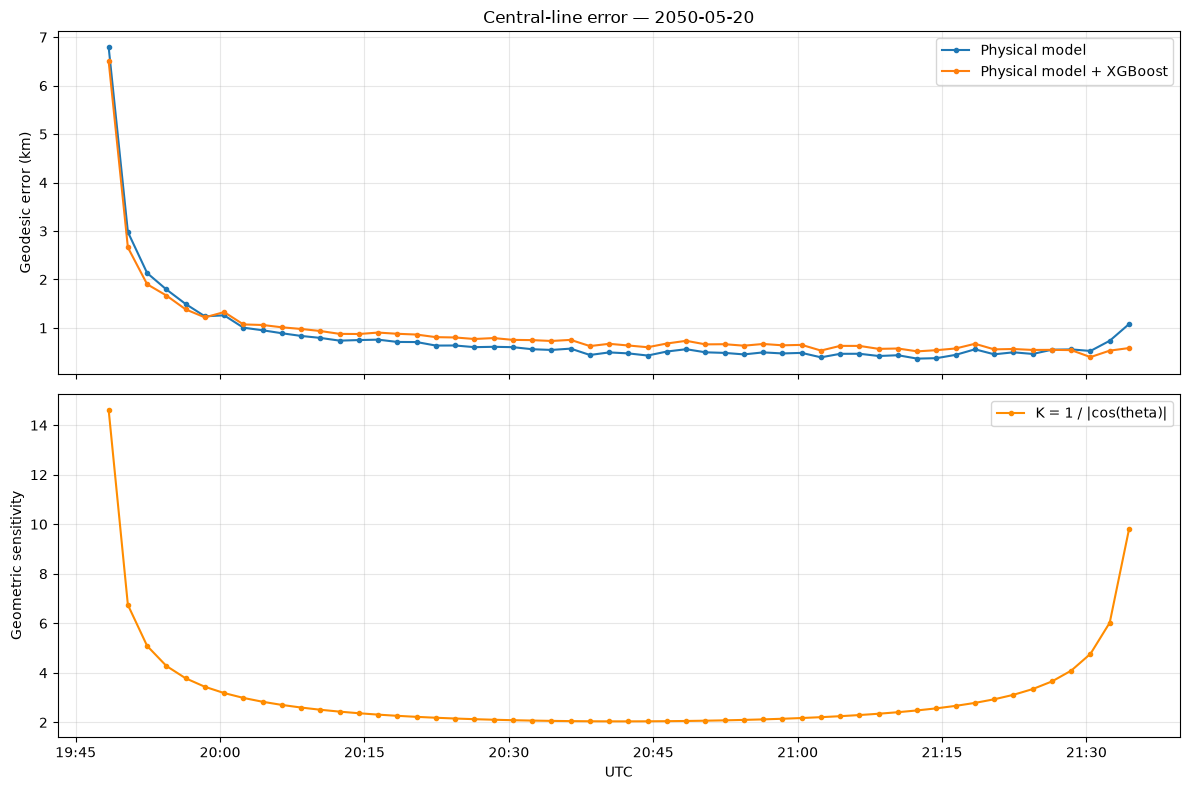

,utc,original_error_km,corrected_error_km,theta_deg,K
8235,2050-05-20 19:48:25.316+00:00,6.799261,6.508298,86.079984,14.627618
8236,2050-05-20 19:50:25.316+00:00,2.979352,2.661253,81.471835,6.743290
8237,2050-05-20 19:52:25.316+00:00,2.133001,1.902103,78.661446,5.086316
8238,2050-05-20 19:54:25.316+00:00,1.794501,1.669242,76.479618,4.277320
8239,2050-05-20 19:56:25.316+00:00,1.494508,1.383676,74.657864,3.779542


In [ ]:
plot_date = test_dates[-1]

df_plot = df_evaluation[
    df_evaluation["date"] == plot_date
].copy()

df_plot["utc"] = pd.to_datetime(df_plot["utc"], utc=True)
df_plot = df_plot.sort_values("utc")

fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

axes[0].plot(
    df_plot["utc"],
    df_plot["original_error_km"],
    marker=".",
    label="Physical model"
)

axes[0].plot(
    df_plot["utc"],
    df_plot["corrected_error_km"],
    marker=".",
    label="Physical model + XGBoost"
)

axes[0].set_title(f"Central-line error — {plot_date}")
axes[0].set_ylabel("Geodesic error (km)")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    df_plot["utc"],
    df_plot["K"],
    color="darkorange",
    marker=".",
    label="K = 1 / |cos(theta)|"
)

axes[1].set_xlabel("UTC")
axes[1].set_ylabel("Geometric sensitivity")
axes[1].grid(alpha=0.3)
axes[1].legend()

axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M", tz="UTC")
)

plt.tight_layout()
plt.show()

display(
    df_plot.nlargest(5, "corrected_error_km")[[
        "utc",
        "original_error_km",
        "corrected_error_km",
        "theta_deg",
        "K"
    ]]
)

The next comparison repeats the same calculation on the fitted eclipses. The gap between training and test improvement measures how much of the apparent gain survives on later events.

In [ ]:
def evaluate_corrections(data):
    df = model_2(data)

    _, _, distance_m = GEOD.inv(
        df["corrected_lon"].to_numpy(),
        df["corrected_lat"].to_numpy(),
        df["nasa_lon"].to_numpy(),
        df["nasa_lat"].to_numpy()
    )

    original_error = df["original_error_km"].mean()
    corrected_error = np.mean(distance_m / 1000)

    predicted_correction = np.hypot(
        df["east_correction_km"],
        df["north_correction_km"]
    ).mean()

    return {
        "Original mean error (km)": original_error,
        "Corrected mean error (km)": corrected_error,
        "Mean predicted correction (km)": predicted_correction,
        "Improvement (%)": 100 * (
            1 - corrected_error / original_error
        ) if original_error > 0 else np.nan
    }


comparison = pd.DataFrame({
    "Train": evaluate_corrections(df_train),
    "Test": evaluate_corrections(df_test)
}).T

display(comparison)

,Original mean error (km),Corrected mean error (km),Mean predicted correction (km),Improvement (%)
Train,0.538563,0.232120,0.409940,56.900165
Test,0.510176,0.454507,0.270207,10.911627


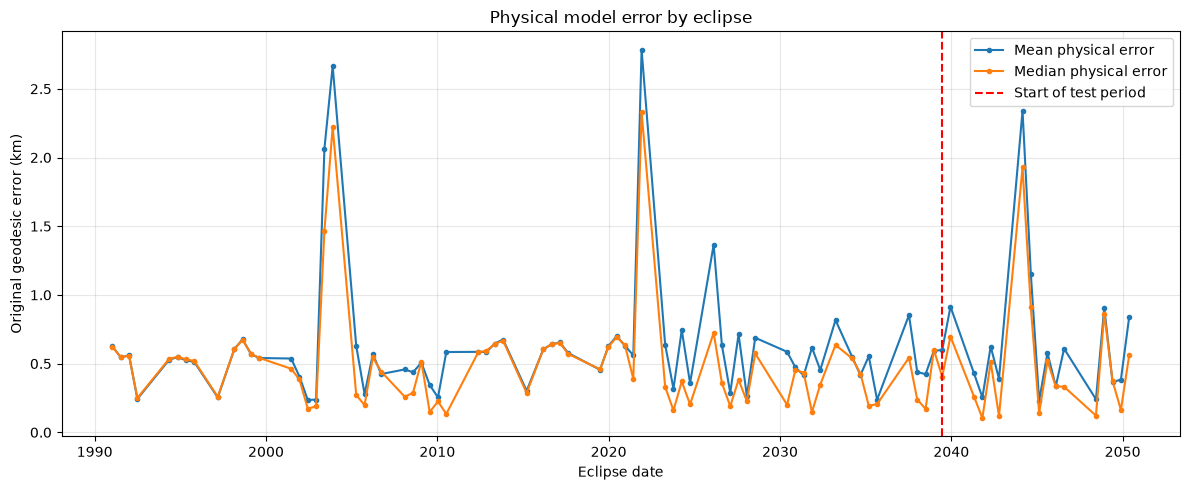

,date,points,mean_error_km,median_error_km,maximum_error_km,maximum_K
70,2041-04-30,96,0.428431,0.259348,3.169602,6.232801
71,2041-10-25,101,0.254174,0.103762,4.400454,9.516213
72,2042-04-20,99,0.624622,0.511056,4.850461,8.592358
73,2042-10-14,114,0.389480,0.119461,10.199970,20.136847
74,2044-02-28,7,2.340104,1.927484,4.826128,36.331127
75,2044-08-23,28,1.151681,0.908501,3.358116,27.541255
76,2045-02-16,58,0.228238,0.140419,2.593144,6.803113
77,2045-08-12,100,0.578741,0.518756,2.545062,6.983821
78,2046-02-05,82,0.334841,0.335017,1.404477,8.423504
79,2046-08-02,89,0.608853,0.331747,7.689536,14.364126


In [ ]:
error_by_date = df_training.groupby("date").agg(
    points=("original_error_km", "size"),
    mean_error_km=("original_error_km", "mean"),
    median_error_km=("original_error_km", "median"),
    maximum_error_km=("original_error_km", "max"),
    maximum_K=("K", "max")
).reset_index()

error_by_date["date"] = pd.to_datetime(error_by_date["date"])

plt.figure(figsize=(12, 5))

plt.plot(
    error_by_date["date"],
    error_by_date["mean_error_km"],
    marker=".",
    label="Mean physical error"
)

plt.plot(
    error_by_date["date"],
    error_by_date["median_error_km"],
    marker=".",
    label="Median physical error"
)

plt.axvline(
    pd.to_datetime(test_dates[0]),
    color="red",
    linestyle="--",
    label="Start of test period"
)

plt.xlabel("Eclipse date")
plt.ylabel("Original geodesic error (km)")
plt.title("Physical model error by eclipse")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

display(error_by_date.tail(15))

## Why the final map uses the physical path

The recorded test included **17 eclipses and 1,329 matched points**, following 68 training eclipses. The mean displacement fell from **0.510 km to 0.455 km**, about **56 m** using the unrounded means. The RMS distance fell from 0.833 to 0.656 km. Some large misses did improve. Across all test points, however, only 54.78% moved closer to NASA. On 30 April 2041 the event mean actually rose from 0.428 to 0.561 km.

Training error fell by 56.9%, compared with 10.9% on the later eclipses. For a map meant to show which regions the shadow crossed, the aligned physical approximation was already satisfactory. The modest and uneven gain did not justify adding two regressors to the trajectory calculation. Eclipse Lab therefore uses the physical central line. The experiment below retains the fitted corrections so the comparison can be reproduced.

In [ ]:
model_2_estimators["east"].save_model("model_2_east.json")
model_2_estimators["north"].save_model("model_2_north.json")

print("Both model 2 regressors were saved.")

In [ ]:
model_2_estimators = {}

for direction in ("east", "north"):
    estimator = XGBRegressor()
    estimator.load_model(f"model_2_{direction}.json")
    model_2_estimators[direction] = estimator

print("Both model 2 regressors were loaded.")

In [ ]:
prediction_date = "2024-04-08"

result = run(
    prediction_date,
    apply_correction=True
)

if result is not None:
    df_dynamics = result["dynamics"]

    df_corrected_path = df_dynamics.dropna(
        subset=["corrected_lat", "corrected_lon"]
    ).copy()

    display(
        df_corrected_path[[
            "utc",
            "lat",
            "lon",
            "east_correction_km",
            "north_correction_km",
            "corrected_lat",
            "corrected_lon"
        ]]
    )

    df_corrected_path.to_csv(
        f"corrected_path_{prediction_date}.csv",
        index=False
    )

    if df_corrected_path.empty:
        print("No central-line intersections were found for this date.")
    else:
        print("Corrected trajectory saved.")